# CSMODEL MCO — Student Sleep, Screen Time & Academic Performance

**Status: partial implementation (MCO1 foundation).** Code cells tagged `[AI-ASSISTED]` were drafted with AI and must be reviewed/understood by the group; cells tagged `[STUDENT TODO]` are for the group to write. All Markdown explanations must be written by the students.

## 1. Abstract

> **[STUDENTS TO WRITE]** This study investigates the relationship between students' sleep patterns, screen time habits, and academic performance. Using an original dataset of 500 student records, reduced to 491 records after data cleaning, the research examines how daily screen usage and screen exposure before bedtime relate to sleep duration, sleep quality, and CGPA. The findings show that students average 6.61 hours of sleep on weekdays, with approximately 59.7% getting fewer than seven hours. Screen time before bedtime has a negative correlation with both sleep duration and sleep quality, while sleep duration has a positive correlation with academic performance, or their CGPA. On the other hand, total daily screen time shows little to no correlation with these outcomes. These findings suggest that screen usage before bedtime may be more closely associated with students' sleep patterns than overall daily screen time.

## 2. Dataset Description

> **[STUDENTS TO WRITE]** Source, collection method and its implications, row/column meaning, attribute descriptions.
The dataset was obtained from Kaggle ("Student Sleep, Screen Time & Academic Performance" by Muhammad Aamir). It is important to note that the dataset is synthetically generated meaning it was not collected from real students. It was created programmatically using randomized sampling to simulate real world data. The creator of the dataset intentionally put human error to simulate real world messiness, like inconsistent capitalization in the gender column, missing values scattered across 5 columns at varying rates and a few injected outliers to help make it more realistic. The dataset contains 500 rows representing each student and 25 columns. Some key variables include academic performance, sleep metrics, screen time, and demographics. Because the data are simulated, every relationship in it is one the generator produced; the analysis therefore illustrates a plausible pattern rather than describing real students, and no result below should be read as evidence about a population.

In [ ]:
import piplite
await piplite.install('seaborn')

In [ ]:
# [AI-ASSISTED] Setup and loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "student_sleep_screen_time_academic_performance.csv"
raw = pd.read_csv(DATA_PATH)   # original, never modified
df = raw.copy()                # working copy used for all cleaning/analysis

print(raw.shape)
raw.dtypes

(500, 25)


student_id                       str
age                            int64
gender                           str
year_of_study                  int64
major_category                   str
residence_type                   str
chronotype                       str
avg_bedtime_hour             float64
avg_sleep_hours_weekday      float64
weekend_sleep_delta_hours    float64
pre_sleep_screen_time_min      int64
daily_screen_time_hours      float64
primary_device                   str
device_free_before_bed           str
caffeine_drinks_per_day        int64
naps_per_week                  int64
sleep_quality_score          float64
exercise_days_per_week         int64
energy_level                 float64
concentration_difficulty     float64
weekly_study_hours           float64
class_attendance_percent     float64
has_part_time_job                str
semester_type                    str
cgpa                         float64
dtype: object

In [ ]:
# [AI-ASSISTED] Numerical summary and categorical value counts
display(raw.describe().T)
cat_cols = raw.select_dtypes(exclude="number").columns.drop("student_id")
for c in cat_cols:
    print(c, raw[c].value_counts(dropna=False).to_dict())

,count,mean,std,min,25%,50%,75%,max
age,500.0,20.260000,1.994079,17.00,19.000,20.00,22.000,27.00
year_of_study,500.0,2.954000,1.405644,1.00,2.000,3.00,4.000,5.00
avg_bedtime_hour,500.0,12.778200,10.772656,0.00,1.100,21.50,22.800,24.00
avg_sleep_hours_weekday,500.0,6.608200,1.435784,1.50,5.700,6.60,7.700,10.50
weekend_sleep_delta_hours,500.0,1.540600,0.965441,-1.00,0.900,1.50,2.200,4.40
pre_sleep_screen_time_min,500.0,38.388000,23.573478,0.00,22.000,35.50,54.000,240.00
daily_screen_time_hours,500.0,5.827000,2.046193,0.50,4.475,5.80,7.200,19.50
caffeine_drinks_per_day,500.0,1.502000,1.273279,0.00,1.000,1.00,2.000,7.00
naps_per_week,500.0,1.458000,1.331082,0.00,0.000,1.00,2.000,7.00
sleep_quality_score,494.0,7.271255,2.131409,1.00,6.000,7.00,9.000,10.00


gender {'Female': 190, 'Male': 180, 'male': 30, 'female': 28, 'F': 24, 'M': 23, 'Non-binary': 13, 'Prefer not to say': 12}
major_category {'STEM': 162, 'Business': 89, 'Social Sciences': 77, 'Health Sciences': 62, 'Humanities': 52, 'Arts': 33, 'Law': 25}
residence_type {'Dormitory': 190, 'Off-campus Apartment': 153, 'With Family': 133, 'Homestay': 24}
chronotype {'Intermediate': 201, 'Early Bird': 152, 'Night Owl': 147}
primary_device {'Smartphone': 271, 'Laptop': 198, 'Tablet': 31}
device_free_before_bed {'No': 368, 'Yes': 123, nan: 9}
has_part_time_job {'No': 331, 'Yes': 169}
semester_type {'Fall': 225, 'Spring': 201, 'Summer': 74}


## 3. Data Cleaning & Preprocessing

> **[STUDENTS TO WRITE]** Justify every cleaning decision (and every step you chose NOT to apply).
>
> ### Missing values and duplicates
> **Identification of Missing Data**: An initial assessment of the raw dataset revealed missing values distributed across five variables: device_free_before_bed (9 missing, 1.8%), sleep_quality_score (6 missing, 1.2%), energy_level (15 missing, 3.0%), concentration_difficulty (14 missing, 2.8%), and cgpa (7 missing, 1.4%). Because these missing entries represent less than 3.5% of total observations per column, they fall within an acceptable threshold where standard imputation or selective dropping can be applied without introducing severe bias.
>
> **Uniqueness and Duplicate Checking**: Both fully duplicated rows and duplicate student_id entries were evaluated to ensure record uniqueness. The checks confirmed 0 fully duplicated rows and 0 duplicate student IDs, verifying that each record in the dataset corresponds to a unique student participant. Consequently, no row-level deduplication is required at this stage.
>
> ### IQR outlier screen
> **Methodology Selection**: To detect potential anomalies without prematurely discarding information, the Interquartile Range (IQR) method was applied using the standard $1.5 \times \text{IQR}$ rule across key numerical columns: avg_sleep_hours_weekday, daily_screen_time_hours, pre_sleep_screen_time_min, weekly_study_hours, class_attendance_percent, and cgpa
>
> **Conservative Flagging Strategy**: Following a non-destructive approach, values falling outside the lower ($Q1 - 1.5 \times \text{IQR}$) and upper ($Q3 + 1.5 \times \text{IQR}$) fences were flagged rather than automatically removed. This ensures that extreme behavioral variations (such as exceptionally high study hours or screen times) are preserved, as they may represent valid behavioral extremes among students rather than data collection artifacts.
>
> ### Inspect avg_bedtime_hour encoding
> **Inspection Purpose**: To understand how student sleep schedules and post-midnight bedtimes are numerically represented, a descriptive statistical analysis (describe()) was conducted on the avg_bedtime_hour feature.
>
> **Distribution Analysis**: The summary statistics across all 500 records show a minimum value of $0.00$ and a maximum value of $24.00$, indicating a continuous 24-hour time scale format. The median ($50\%$) value of $21.50$ (9:30 PM) combined with a first quartile ($25\%$) of $1.10$ (approx. 1:06 AM) demonstrates that student sleep patterns span across midnight, capturing both early and late sleepers.
>
> **Completeness**: The count of $500.00$ confirms that there are no missing entries in this feature, ensuring high data integrity and reliability for subsequent sleep behavior analyses.
>
> ### Cleaning on the working copy: label consistency + bedtime wrap-around
> **Categorical Label Standardization**: To correct inconsistencies and formatting variants in the gender column (such as 'male', 'M', and 'Male'), values were mapped and standardized into unified categories (Female, Male). As shown in the post-cleaning value counts, the distribution across the dataset comprises 242 Female, 233 Male, 13 Non-binary, and 12 Prefer not to say respondents. This standardization prevents fragmentation during grouping, aggregation, and categorical modeling.
>
> **Bedtime Feature Engineering (Midnight Wrap-Around Adjustment)**: Because bedtimes occurring after midnight were natively recorded on a 0–6 hour scale, treating them strictly numerically would distort mathematical models by making late-night sleep look artificially early (e.g., 1:00 AM appearing smaller than 10:00 PM). To resolve this, a continuous shifted scale (bedtime_shifted) was engineered by adding 24 hours to any bedtime values below 12 (e.g., shifting 1:00 AM to 25.0). This maintains chronological continuity for regression and statistical correlation analyses.

In [ ]:
# [AI-ASSISTED] Missing values and duplicates
missing = raw.isna().sum()
display(missing[missing > 0].to_frame("n_missing").assign(pct=lambda t: (t.n_missing / len(raw) * 100).round(1)))
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated student_id:", raw["student_id"].duplicated().sum())

,n_missing,pct
device_free_before_bed,9,1.8
sleep_quality_score,6,1.2
energy_level,15,3.0
concentration_difficulty,14,2.8
cgpa,7,1.4


Fully duplicated rows: 0
Duplicated student_id: 0


In [ ]:
# [AI-ASSISTED] IQR outlier screen (flags only; nothing is removed here)
num_cols = ["avg_sleep_hours_weekday", "daily_screen_time_hours", "pre_sleep_screen_time_min",
            "weekly_study_hours", "class_attendance_percent", "cgpa"]
rows = []
for c in num_cols:
    s = raw[c].dropna()
    q1, q3 = s.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append((c, round(lo, 2), round(hi, 2), int(((s < lo) | (s > hi)).sum()), s.min(), s.max()))
pd.DataFrame(rows, columns=["variable", "lower_fence", "upper_fence", "n_flagged", "min", "max"])

,variable,lower_fence,upper_fence,n_flagged,min,max
0,avg_sleep_hours_weekday,2.70,10.70,2,1.50,10.50
1,daily_screen_time_hours,0.39,11.29,2,0.50,19.50
2,pre_sleep_screen_time_min,-26.00,102.00,3,0.00,240.00
3,weekly_study_hours,-0.24,32.66,3,0.00,88.50
4,class_attendance_percent,45.05,113.65,3,34.60,100.00
5,cgpa,1.98,3.69,6,1.89,3.95


In [ ]:
# [AI-ASSISTED] Inspect avg_bedtime_hour encoding (check how post-midnight bedtimes are stored)
raw["avg_bedtime_hour"].describe()

count    500.000000
mean      12.778200
std       10.772656
min        0.000000
25%        1.100000
50%       21.500000
75%       22.800000
max       24.000000
Name: avg_bedtime_hour, dtype: float64

In [ ]:
# [AI-ASSISTED] Cleaning on the working copy: label consistency + bedtime wrap-around
# Gender has variants of the same label (e.g. 'male', 'M', 'Male').
df["gender"] = df["gender"].replace({"male": "Male", "M": "Male", "female": "Female", "F": "Female"})

# Bedtimes after midnight are stored as 0-6; shift by +24 so 1am becomes 25.0 (continuous scale).
df["bedtime_shifted"] = np.where(df["avg_bedtime_hour"] < 12, df["avg_bedtime_hour"] + 24, df["avg_bedtime_hour"])
df["gender"].value_counts()

gender
Female               242
Male                 233
Non-binary            13
Prefer not to say     12
Name: count, dtype: int64

In [ ]:
# [STUDENT TODO] Decide and implement handling of missing values
# (cgpa, sleep_quality_score, energy_level, concentration_difficulty, device_free_before_bed)
# and of the flagged outliers. Justify in the Markdown above.
df = df.dropna(subset=["cgpa"]).copy()

score_cols = ["sleep_quality_score", "energy_level", "concentration_difficulty"]
df[score_cols] = df[score_cols].fillna(df[score_cols].median())

df["device_free_before_bed"] = df["device_free_before_bed"].fillna("Unknown")

impossible = (df["daily_screen_time_hours"] + df["avg_sleep_hours_weekday"] > 24) | (df["weekly_study_hours"] > 84)
display(df.loc[impossible, ["student_id", "daily_screen_time_hours", "avg_sleep_hours_weekday", "weekly_study_hours"]])
df = df[~impossible].copy()

print("Rows kept:", len(df), "of", len(raw), "| remaining missing cells:", int(df.isna().sum().sum()))

,student_id,daily_screen_time_hours,avg_sleep_hours_weekday,weekly_study_hours
449,STU2450,19.5,4.6,17.7
462,STU2463,7.4,6.7,88.5


Rows kept: 491 of 500 | remaining missing cells: 0


In [ ]:
# [STUDENT TODO] Feature engineering for later sections, e.g. sleep-duration groups, screen-time groups
df["sleep_group"] = pd.cut(df["avg_sleep_hours_weekday"], bins=[0, 6, 8, 24], right=False,
                           labels=["Short (<6h)", "Moderate (6-8h)", "Long (8h+)"])

df["screen_group"] = pd.qcut(df["daily_screen_time_hours"], q=3, labels=["Low", "Medium", "High"])

df["pre_sleep_group"] = pd.cut(df["pre_sleep_screen_time_min"], bins=[-1, 30, 60, np.inf],
                               labels=["0-30 min", "31-60 min", "60+ min"])

for c in ["sleep_group", "screen_group", "pre_sleep_group"]:
    print(c, df[c].value_counts().sort_index().to_dict())

sleep_group {'Short (<6h)': 152, 'Moderate (6-8h)': 244, 'Long (8h+)': 95}
screen_group {'Low': 167, 'Medium': 164, 'High': 160}
pre_sleep_group {'0-30 min': 197, '31-60 min': 214, '60+ min': 80}


## 4. Research Question & Exploratory Data Analysis

**Research question.** How are students' sleep duration and screen time associated with their
academic performance (CGPA)?

The wording is associational: the data are cross-sectional, so the analysis describes patterns of
co-variation rather than effects. Three questions follow, each with one figure - what students'
sleep and screen habits look like, whether screen time is related to sleep, and whether sleep is
related to grades. The cleaned data contain 491 students.

### EDA Question 1

**[STUDENTS TO WRITE]** **How are weekday sleep duration, bedtime and daily screen time distributed, and how many students
fall outside the recommended 7-9 hours of sleep?**

This is the descriptive baseline: before relating sleep to grades, we need to know how much sleep
students get, when they go to bed, and how much of the day screens take up. The 7-9 hour band is the
National Sleep Foundation recommendation for young adults, which gives an external benchmark.
Bedtime is described here as context; the grade question in question 3 is about sleep duration.

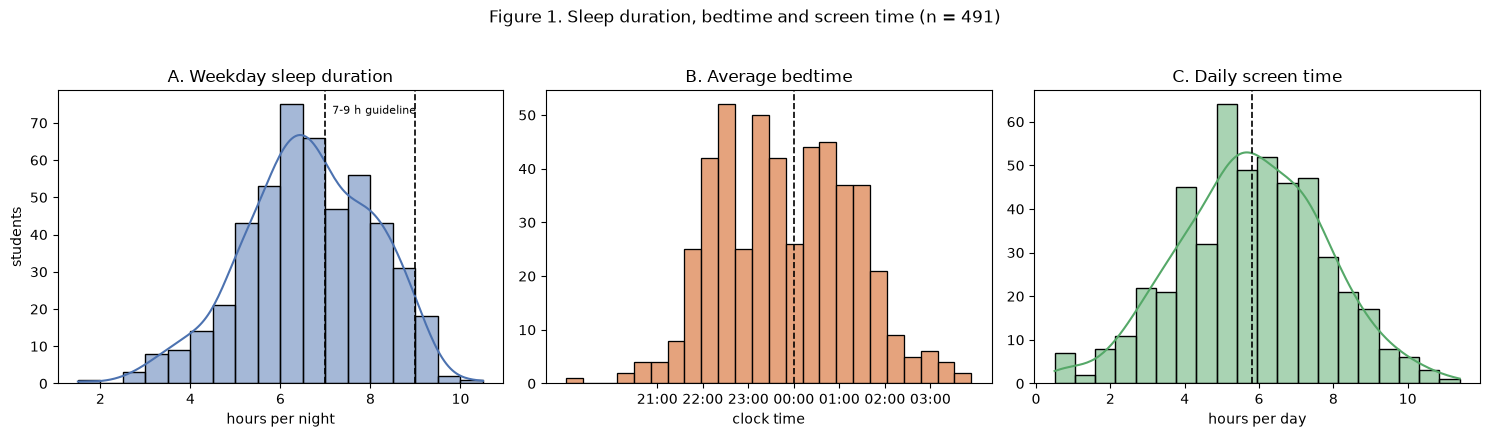

,count,mean,std,min,25%,50%,75%,max
avg_sleep_hours_weekday,491.0,6.61,1.44,1.5,5.7,6.6,7.7,10.5
bedtime_shifted,491.0,23.82,1.46,19.0,22.6,23.7,24.9,27.9
daily_screen_time_hours,491.0,5.80,1.96,0.5,4.5,5.8,7.2,11.4
pre_sleep_screen_time_min,491.0,38.42,23.69,0.0,22.0,36.0,54.0,240.0


sleep < 7 h: 59.7%   |   7-9 h: 38.1%   |   > 9 h: 2.2%
median bedtime 23:42   |   asleep at/after midnight: 46.0%
median daily screen 5.8 h   |   more than 8 h: 12.2%   |   median before bed: 36 min


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.histplot(df["avg_sleep_hours_weekday"], bins=18, kde=True, ax=axes[0], color="#4C72B0")
for x in (7, 9):
    axes[0].axvline(x, ls="--", lw=1.2, c="black")
axes[0].set(title="A. Weekday sleep duration", xlabel="hours per night", ylabel="students")
axes[0].text(7.15, axes[0].get_ylim()[1] * 0.92, "7-9 h guideline", fontsize=8)

sns.histplot(df["bedtime_shifted"], bins=24, ax=axes[1], color="#DD8452")
axes[1].axvline(24, ls="--", lw=1.2, c="black")
axes[1].set(title="B. Average bedtime", xlabel="clock time", ylabel="")
axes[1].set_xticks([21, 22, 23, 24, 25, 26, 27])
axes[1].set_xticklabels(["21:00", "22:00", "23:00", "00:00", "01:00", "02:00", "03:00"])

sns.histplot(df["daily_screen_time_hours"], bins=20, kde=True, ax=axes[2], color="#55A868")
axes[2].axvline(df["daily_screen_time_hours"].median(), ls="--", lw=1.2, c="black")
axes[2].set(title="C. Daily screen time", xlabel="hours per day", ylabel="")

fig.suptitle(f"Figure 1. Sleep duration, bedtime and screen time (n = {len(df)})", y=1.03)
plt.tight_layout()
plt.show()

display(df[["avg_sleep_hours_weekday", "bedtime_shifted", "daily_screen_time_hours",
            "pre_sleep_screen_time_min"]].describe().T.round(2))

print(f"sleep < 7 h: {(df.avg_sleep_hours_weekday < 7).mean():.1%}"
      f"   |   7-9 h: {df.avg_sleep_hours_weekday.between(7, 9).mean():.1%}"
      f"   |   > 9 h: {(df.avg_sleep_hours_weekday > 9).mean():.1%}")
bed = df["bedtime_shifted"].median()
print(f"median bedtime {int(bed) % 24:02d}:{int(round((bed % 1) * 60)) % 60:02d}"
      f"   |   asleep at/after midnight: {(df.bedtime_shifted >= 24).mean():.1%}")
print(f"median daily screen {df.daily_screen_time_hours.median():.1f} h"
      f"   |   more than 8 h: {(df.daily_screen_time_hours > 8).mean():.1%}"
      f"   |   median before bed: {df.pre_sleep_screen_time_min.median():.0f} min")

**Reading Figure 1.** Weekday sleep averages 6.6 hours and sits left of the guideline:
59.7% of students sleep under 7 hours, only 38.1% fall inside the 7-9 hour band, and 2.2% sleep more
than 9. The median bedtime is 23:42, and 46.0% of the sample is asleep at or after midnight, so late
nights are typical rather than exceptional. Screen time is concentrated around 5.8 hours a day, with
the mean and median agreeing, and 12.2% of students exceed 8 hours. The measure that matters later is
much smaller: the median student reports 36 minutes of screen use before bed.

### EDA Question 2

**[STUDENTS TO WRITE]** **Is screen time associated with sleep, and does it matter whether the screen time happens across
the whole day or right before bed?**

If screen time were uniformly harmful, total daily hours and pre-sleep minutes would both show the
same negative relationship with sleep. If timing matters more, the pre-sleep measure should carry
the signal while total daily use stays near zero.

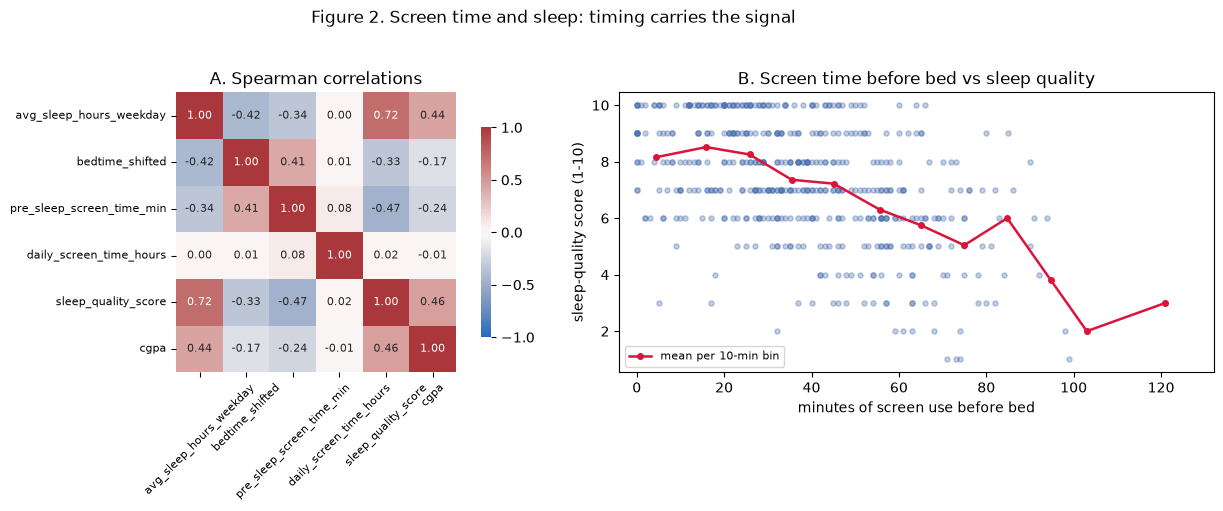

,pearson,spearman
daily_screen_time_hours x avg_sleep_hours_weekday,-0.013,0.002
daily_screen_time_hours x sleep_quality_score,0.024,0.017
daily_screen_time_hours x cgpa,-0.022,-0.012
pre_sleep_screen_time_min x avg_sleep_hours_weekday,-0.296,-0.335
pre_sleep_screen_time_min x sleep_quality_score,-0.436,-0.467
pre_sleep_screen_time_min x bedtime_shifted,0.384,0.411
pre_sleep_screen_time_min x cgpa,-0.219,-0.238


,n,sleep_hours,bedtime,sleep_quality,cgpa,daily_screen
pre_sleep_group,,,,,,
0-30 min,197,7.14,23.21,8.31,2.92,5.57
31-60 min,214,6.42,24.02,7.01,2.81,5.86
60+ min,80,5.82,24.78,5.42,2.72,6.18


In [ ]:
corr_vars = ["avg_sleep_hours_weekday", "bedtime_shifted", "pre_sleep_screen_time_min",
             "daily_screen_time_hours", "sleep_quality_score", "cgpa"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})

sns.heatmap(df[corr_vars].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, square=True, ax=axes[0],
            cbar_kws={"shrink": .75}, annot_kws={"size": 8})
axes[0].set_title("A. Spearman correlations")
axes[0].tick_params(axis="x", rotation=45, labelsize=8)
axes[0].tick_params(axis="y", labelsize=8)

axes[1].scatter(df["pre_sleep_screen_time_min"], df["sleep_quality_score"],
                s=14, alpha=.35, color="#4C72B0")
tmp = df[df["pre_sleep_screen_time_min"] <= 130].copy()
tmp["bin"] = pd.cut(tmp["pre_sleep_screen_time_min"], np.arange(0, 131, 10), include_lowest=True)
trend = tmp.groupby("bin", observed=True).agg(x=("pre_sleep_screen_time_min", "mean"),
                                              y=("sleep_quality_score", "mean"))
axes[1].plot(trend["x"], trend["y"], "o-", color="crimson", lw=1.8, ms=4,
             label="mean per 10-min bin")
axes[1].set(title="B. Screen time before bed vs sleep quality",
            xlabel="minutes of screen use before bed",
            ylabel="sleep-quality score (1-10)", xlim=(-4, 132))
axes[1].legend(fontsize=8, loc="lower left")

fig.suptitle("Figure 2. Screen time and sleep: timing carries the signal", y=1.03)
plt.tight_layout()
plt.show()

pairs = [("daily_screen_time_hours", "avg_sleep_hours_weekday"),
         ("daily_screen_time_hours", "sleep_quality_score"),
         ("daily_screen_time_hours", "cgpa"),
         ("pre_sleep_screen_time_min", "avg_sleep_hours_weekday"),
         ("pre_sleep_screen_time_min", "sleep_quality_score"),
         ("pre_sleep_screen_time_min", "bedtime_shifted"),
         ("pre_sleep_screen_time_min", "cgpa")]
display(pd.DataFrame({"pearson": [df[a].corr(df[b]) for a, b in pairs],
                      "spearman": [df[a].corr(df[b], method="spearman") for a, b in pairs]},
                     index=[f"{a} x {b}" for a, b in pairs]).round(3))

display(df.groupby("pre_sleep_group", observed=True).agg(
    n=("student_id", "size"),
    sleep_hours=("avg_sleep_hours_weekday", "mean"),
    bedtime=("bedtime_shifted", "mean"),
    sleep_quality=("sleep_quality_score", "mean"),
    cgpa=("cgpa", "mean"),
    daily_screen=("daily_screen_time_hours", "mean")).round(2))

**Reading Figure 2.** The two screen measures behave differently. Total daily screen time
is essentially unrelated to sleep: the Spearman correlation is 0.00 with sleep duration, 0.02 with
sleep quality and -0.01 with CGPA, so "students who use screens a lot sleep badly" is not what these
data show. Screen time before bed is the informative measure, at -0.34 with sleep duration, -0.47
with sleep quality and +0.41 with later bedtimes. The grouped table makes the size concrete: students
reporting more than an hour before bed sleep 5.8 hours against 7.1 for those who stop at 30 minutes,
rate their sleep 5.4 against 8.3 on the ten-point scale, and average a CGPA of 2.72 against 2.92,
while their total daily screen time differs by only about half an hour (6.2 against 5.6 hours).

### EDA Question 3

**[STUDENTS TO WRITE]** **Is CGPA higher for students who sleep longer?**

This is the question the analysis builds towards. Two views are used: CGPA by sleep group, and sleep
duration against CGPA directly.

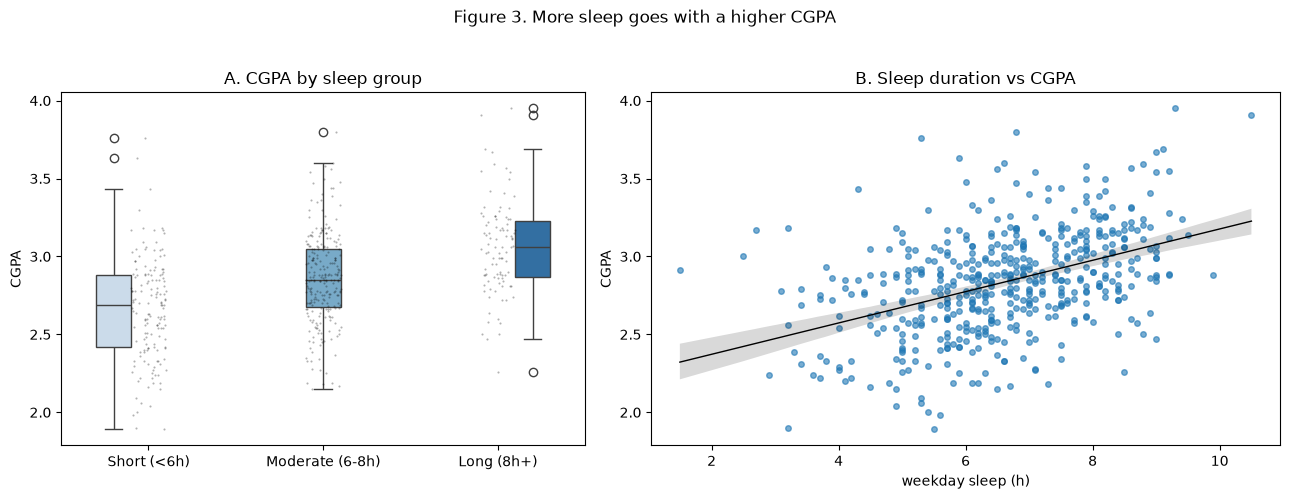

,count,mean,median
sleep_group,,,
Short (<6h),152,2.66,2.69
Moderate (6-8h),244,2.86,2.85
Long (8h+),95,3.06,3.06


r(sleep hours, CGPA) = 0.433   |   r(sleep quality, CGPA) = 0.467
within-chronotype r(sleep hours, CGPA):
  Early Bird     n=149  r=+0.409
  Intermediate   n=199  r=+0.349
  Night Owl      n=143  r=+0.276
context: r(attendance, CGPA) = 0.254   |   r(attendance, sleep hours) = 0.337   |   r(study hours, CGPA) = 0.326


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})

sns.boxplot(data=df, x="sleep_group", y="cgpa", hue="sleep_group", legend=False,
            palette="Blues", width=.6, ax=axes[0])
sns.stripplot(data=df, x="sleep_group", y="cgpa", color="black", size=1.5, alpha=.3, ax=axes[0])
axes[0].set(title="A. CGPA by sleep group", xlabel="", ylabel="CGPA")

sns.regplot(data=df, x="avg_sleep_hours_weekday", y="cgpa", ax=axes[1],
            scatter_kws={"s": 16, "alpha": .6}, line_kws={"color": "black", "lw": 1})
axes[1].set(title="B. Sleep duration vs CGPA", xlabel="weekday sleep (h)", ylabel="CGPA")

fig.suptitle("Figure 3. More sleep goes with a higher CGPA", y=1.03)
plt.tight_layout()
plt.show()

display(df.groupby("sleep_group", observed=True)["cgpa"].agg(["count", "mean", "median"]).round(2))

print(f"r(sleep hours, CGPA) = {df.avg_sleep_hours_weekday.corr(df.cgpa):.3f}"
      f"   |   r(sleep quality, CGPA) = {df.sleep_quality_score.corr(df.cgpa):.3f}")
print("within-chronotype r(sleep hours, CGPA):")
for name, g in df.groupby("chronotype"):
    print(f"  {name:<14} n={len(g):>3}  r={g.avg_sleep_hours_weekday.corr(g.cgpa):+.3f}")
print(f"context: r(attendance, CGPA) = {df.class_attendance_percent.corr(df.cgpa):.3f}"
      f"   |   r(attendance, sleep hours) = {df.class_attendance_percent.corr(df.avg_sleep_hours_weekday):.3f}"
      f"   |   r(study hours, CGPA) = {df.weekly_study_hours.corr(df.cgpa):.3f}")

**Reading Figure 3.** CGPA rises with sleep duration: 2.66 in the short group, 2.86 in the
moderate group and 3.06 in the eight-hour-plus group, a difference of about 0.4 of a grade point,
and the scatter in panel B gives a correlation of 0.43. Sleep quality tracks CGPA slightly more
closely at 0.47. The pattern is not simply a matter of chronotype: within early birds, intermediates
and night owls the correlation stays positive at 0.41, 0.35 and 0.28. Attendance is associated with
both sleep (0.34) and CGPA (0.25), and study hours with CGPA (0.33), but a cross-sectional snapshot
cannot say whether attendance is a mediator, a confounder or simply another associated variable.

## 5. Data Mining

> **[RESERVED FOR MCO2]** Rule mining, clustering, or collaborative filtering.

## 6. Statistical Inference

> **[RESERVED FOR MCO2]** At least two tests with hypotheses, assumption checks, p-values and significance level.

## 7. Summary, Conclusions, and Recommendations

> **[RESERVED FOR MCO2]**

## 8. References & Disclosures

> **[STUDENTS TO WRITE]** List references and add the generative-AI disclosure statement in the format required by the specs (tool name, purposes of use, review statement).